# Actividad de Evaluación 1 – Unidad II
## Exploración, clasificación y diagnóstico del conjunto de datos

| | |
|---|---|
| **Alumna** | Brisa Adriana Mendoza Vigueras |
| **Grupo** | 10IDGS-G1 |
| **Proyecto** | Análisis del rendimiento académico de estudiantes |
| **Dataset** | Student Performance (UCI Machine Learning Repository) |
| **Archivo** | `data/raw/student-por.csv` |

> En esta actividad **no se elimina ni se modifica** ningún dato. El archivo original solo se lee;
> las variables auxiliares que se calculan se guardan aparte y nunca se agregan al DataFrame `df`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 100

RUTA = Path("../data/raw/student-por.csv")
FIG = Path("../docs/figuras")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Identificación del dataset

| Concepto | Descripción |
|---|---|
| Proyecto | Análisis del rendimiento académico de estudiantes |
| Dataset | Student Performance |
| Fuente | UCI Machine Learning Repository – https://archive.ics.uci.edu/dataset/320/student+performance (DOI 10.24432/C5TG7T). Autor: Paulo Cortez, Universidad do Minho (Cortez y Silva, 2008) |
| Formato | CSV (texto separado por **punto y coma** `;`) |
| Registros y variables | Se obtienen con `df.shape` en la siguiente sección |
| Descripción general | Información de alumnos de bachillerato de dos escuelas de Portugal (curso de Portugués): calificaciones de tres periodos (G1, G2, G3) y datos demográficos, familiares, sociales y de hábitos de estudio, obtenidos de reportes escolares y cuestionarios |

## 2. Carga y exploración inicial

Se lee el archivo con `pd.read_csv`. Como el separador no es coma, se indica `sep=";"`.

In [2]:
df = pd.read_csv(RUTA, sep=";")

### 2.1 `df.head()` – primeros registros

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


**Interpretación:** cada fila es un alumno y cada columna una característica. Se observan variables de
texto (`school`, `sex`, `Mjob`, `higher`...) y numéricas (`age`, `Medu`, `absences`, `G1`, `G2`, `G3`).
Los datos se cargaron correctamente: las columnas quedaron separadas y los nombres coinciden con la
documentación del dataset.

### 2.2 `df.shape` – dimensiones

In [4]:
df.shape

(649, 33)

**Interpretación:** el dataset tiene **649 registros** (alumnos) y **33 variables**: 30 características
del alumno y 3 calificaciones (`G1`, `G2` y `G3`). Es un tamaño pequeño, que se procesa sin problema en una
computadora personal.

### 2.3 `df.columns` – nombres de las variables

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

**Interpretación:** los nombres son abreviaturas en inglés (por ejemplo `Medu` = *mother's education*,
`Dalc` = *daily alcohol*). Por eso es necesario el diccionario de datos de la sección 3. No hay nombres
repetidos ni con espacios.

### 2.4 `df.info()` – tipos de dato y valores no nulos

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  
 21  inte

**Interpretación:** las 33 columnas tienen **649 valores no nulos**, es decir, no hay datos faltantes.
Hay 16 columnas enteras (`int64`) y 17 de texto (`object` o `str`, según la versión de pandas). El tamaño
en memoria es muy bajo.

### 2.5 `df.dtypes` – tipo de dato por variable

In [7]:
df.dtypes

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

In [8]:
df.dtypes.astype(str).value_counts()

str      17
int64    16
Name: count, dtype: int64

**Interpretación:** los tipos detectados por pandas son correctos para su contenido. Hay un detalle importante:
algunas variables guardadas como `int64` **no son cantidades**, sino **escalas ordinales** codificadas con
números (`Medu`, `Fedu`, `studytime`, `famrel`, `Dalc`, `health`...). Un 4 en `studytime` no significa
"4 horas", sino "más de 10 horas". Esto se registra en el diccionario de datos.

### 2.6 `df.describe()` – estadística descriptiva

In [9]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,649.0,16.74,1.22,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.51,1.13,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.31,1.10,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.57,0.75,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.93,0.83,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.22,0.59,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.93,0.96,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.18,1.05,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.18,1.18,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.50,0.92,1.0,1.0,1.0,2.0,5.0


In [10]:
df.describe(exclude='number').T

,count,unique,top,freq
school,649,2,GP,423
sex,649,2,F,383
address,649,2,U,452
famsize,649,2,GT3,457
Pstatus,649,2,T,569
Mjob,649,5,other,258
Fjob,649,5,other,367
reason,649,4,course,285
guardian,649,3,mother,455
schoolsup,649,2,no,581


**Interpretación:**
- `age` va de 15 a 22 años, con media de 16.7.
- `G3` va de 0 a 19 y tiene media de 11.9. Ningún alumno llegó a 20.
- El mínimo de `G1`, `G2` y `G3` es **0**, un valor poco común que se revisa en la sección 5.3.
- `absences` tiene media de 3.7, pero máximo de 32: hay pocos alumnos con muchas faltas (posibles atípicos).
- `failures` tiene mediana 0: la mayoría no ha reprobado materias antes.
- En las categóricas, la moda es: escuela **GP**, sexo **F**, domicilio **urbano** y la mayoría
  **sí quiere estudios superiores** (`higher = yes`).

## 3. Diccionario de datos

In [11]:
diccionario = pd.DataFrame([
    # variable, descripción, tipo de variable, clasificación, unidad, posible utilidad
    ("school", "Escuela: GP Gabriel Pereira, MS Mousinho da Silveira", "Cualitativa", "Nominal binaria", "No aplica", "Comparar desempeño entre escuelas; predictora"),
    ("sex", "Sexo del estudiante (F / M)", "Cualitativa", "Nominal binaria", "No aplica", "Predictora; segmentación del dashboard"),
    ("age", "Edad del estudiante", "Cuantitativa", "Discreta", "Años", "Predictora; edades altas indican rezago"),
    ("address", "Tipo de domicilio: U urbano, R rural", "Cualitativa", "Nominal binaria", "No aplica", "Predictora (contexto socioeconómico)"),
    ("famsize", "Tamaño de la familia: LE3 (<=3), GT3 (>3)", "Cualitativa", "Ordinal binaria", "No aplica", "Predictora de entorno familiar"),
    ("Pstatus", "Situación de los padres: T juntos, A separados", "Cualitativa", "Nominal binaria", "No aplica", "Predictora de entorno familiar"),
    ("Medu", "Escolaridad de la madre (0 ninguna a 4 superior)", "Cualitativa", "Ordinal", "Nivel 0-4", "Predictora; correlación positiva con G3"),
    ("Fedu", "Escolaridad del padre (0 ninguna a 4 superior)", "Cualitativa", "Ordinal", "Nivel 0-4", "Predictora; correlación positiva con G3"),
    ("Mjob", "Trabajo de la madre (teacher, health, services, at_home, other)", "Cualitativa", "Nominal", "No aplica", "Predictora (requiere one-hot)"),
    ("Fjob", "Trabajo del padre (mismas categorías)", "Cualitativa", "Nominal", "No aplica", "Predictora (requiere one-hot)"),
    ("reason", "Motivo de elección de la escuela", "Cualitativa", "Nominal", "No aplica", "Predictora (requiere one-hot)"),
    ("guardian", "Tutor del estudiante (mother, father, other)", "Cualitativa", "Nominal", "No aplica", "Predictora (requiere one-hot)"),
    ("traveltime", "Tiempo de traslado (1 <15 min a 4 >1 h)", "Cualitativa", "Ordinal", "Rango de tiempo", "Predictora; clustering"),
    ("studytime", "Estudio semanal (1 <2 h a 4 >10 h)", "Cualitativa", "Ordinal", "Rango de horas", "Predictora clave; clustering"),
    ("failures", "Materias reprobadas anteriormente (0 a 3)", "Cuantitativa", "Discreta", "Número de materias", "Predictora más fuerte fuera de G1/G2"),
    ("schoolsup", "Apoyo educativo extra de la escuela", "Cualitativa", "Nominal binaria", "No aplica", "Predictora; indica alumnos en riesgo"),
    ("famsup", "Apoyo educativo de la familia", "Cualitativa", "Nominal binaria", "No aplica", "Predictora"),
    ("paid", "Clases extra pagadas de la materia", "Cualitativa", "Nominal binaria", "No aplica", "Predictora"),
    ("activities", "Actividades extracurriculares", "Cualitativa", "Nominal binaria", "No aplica", "Predictora; clustering"),
    ("nursery", "Asistió a guardería/preescolar", "Cualitativa", "Nominal binaria", "No aplica", "Predictora (baja relevancia esperada)"),
    ("higher", "Quiere cursar estudios superiores", "Cualitativa", "Nominal binaria", "No aplica", "Predictora importante (motivación)"),
    ("internet", "Acceso a internet en casa", "Cualitativa", "Nominal binaria", "No aplica", "Predictora (recursos en casa)"),
    ("romantic", "Tiene relación de pareja", "Cualitativa", "Nominal binaria", "No aplica", "Predictora; clustering (vida social)"),
    ("famrel", "Calidad de la relación familiar (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora; clustering"),
    ("freetime", "Tiempo libre después de clases (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora; clustering"),
    ("goout", "Salidas con amigos (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora; clustering"),
    ("Dalc", "Consumo de alcohol entre semana (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora; clustering"),
    ("Walc", "Consumo de alcohol en fin de semana (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora; clustering"),
    ("health", "Estado de salud actual (1 a 5)", "Cualitativa", "Ordinal", "Escala 1-5", "Predictora"),
    ("absences", "Número de faltas a clase", "Cuantitativa", "Discreta", "Número de faltas", "Predictora; clustering"),
    ("G1", "Calificación del primer periodo", "Cuantitativa", "Discreta", "Puntos (0 a 20)", "Predictora (escenario con parciales)"),
    ("G2", "Calificación del segundo periodo", "Cuantitativa", "Discreta", "Puntos (0 a 20)", "Predictora (escenario con parciales)"),
    ("G3", "Calificación final del curso", "Cuantitativa", "Discreta", "Puntos (0 a 20)", "Variable objetivo de regresión; base de la clase aprobado/no aprobado"),
], columns=["variable", "descripcion", "tipo_variable", "clasificacion", "unidad_medida", "posible_utilidad"])

# El tipo de dato en Python se toma directamente del DataFrame
diccionario.insert(2, "tipo_python", diccionario["variable"].map(df.dtypes.astype(str)))
diccionario.to_csv("../docs/diccionario_de_datos.csv", index=False, encoding="utf-8-sig")
diccionario

,variable,descripcion,tipo_python,tipo_variable,clasificacion,unidad_medida,posible_utilidad
0,school,"Escuela: GP Gabriel Pereira, MS Mousinho da Si...",str,Cualitativa,Nominal binaria,No aplica,Comparar desempeño entre escuelas; predictora
1,sex,Sexo del estudiante (F / M),str,Cualitativa,Nominal binaria,No aplica,Predictora; segmentación del dashboard
2,age,Edad del estudiante,int64,Cuantitativa,Discreta,Años,Predictora; edades altas indican rezago
3,address,"Tipo de domicilio: U urbano, R rural",str,Cualitativa,Nominal binaria,No aplica,Predictora (contexto socioeconómico)
4,famsize,"Tamaño de la familia: LE3 (<=3), GT3 (>3)",str,Cualitativa,Ordinal binaria,No aplica,Predictora de entorno familiar
5,Pstatus,"Situación de los padres: T juntos, A separados",str,Cualitativa,Nominal binaria,No aplica,Predictora de entorno familiar
6,Medu,Escolaridad de la madre (0 ninguna a 4 superior),int64,Cualitativa,Ordinal,Nivel 0-4,Predictora; correlación positiva con G3
7,Fedu,Escolaridad del padre (0 ninguna a 4 superior),int64,Cualitativa,Ordinal,Nivel 0-4,Predictora; correlación positiva con G3
8,Mjob,"Trabajo de la madre (teacher, health, services...",str,Cualitativa,Nominal,No aplica,Predictora (requiere one-hot)
9,Fjob,Trabajo del padre (mismas categorías),str,Cualitativa,Nominal,No aplica,Predictora (requiere one-hot)


In [12]:
pd.crosstab(diccionario["clasificacion"], diccionario["tipo_variable"], margins=True, margins_name="Total")

tipo_variable,Cualitativa,Cuantitativa,Total
clasificacion,,,
Discreta,0,6,6
Nominal,4,0,4
Nominal binaria,12,0,12
Ordinal,10,0,10
Ordinal binaria,1,0,1
Total,27,6,33


**Interpretación:**
- **Cuantitativas (6):** `age`, `failures`, `absences`, `G1`, `G2` y `G3` son discretas porque cuentan
  unidades enteras (años, materias, faltas, puntos).
- **Cualitativas (27):**
  - 13 binarias (dos valores).
  - 4 nominales (sin orden).
  - 10 ordinales (`Medu`, `studytime`, las escalas de 1 a 5...). Estas tienen orden aunque estén codificadas
    como número.
- Las nominales y binarias de texto deberán codificarse a números en la siguiente actividad (limpieza y ETL).

## 4. Tipo y fuente de los datos

**Procedencia:** los datos fueron recopilados por Cortez y Silva (2008) durante el ciclo 2005-2006 en dos
escuelas públicas de Portugal, a partir de dos fuentes:

1. **Reportes escolares:** calificaciones (`G1`, `G2`, `G3`), faltas (`absences`) y escuela. Son **datos
   transaccionales o administrativos**: se generan como registro de la operación normal de la escuela
   (cada evaluación o falta queda registrada en el sistema escolar).
2. **Cuestionarios aplicados a los estudiantes:** el resto de las variables, como entorno familiar, tiempo de
   estudio, salidas o consumo de alcohol. Son **datos generados por personas**, porque el propio alumno los
   reporta; por eso pueden tener sesgo de autorreporte.

No provienen de máquinas o sensores, de la web, de medios sociales ni son biométricos.

**Clasificación de la fuente:** **estructurada**. La información está organizada en una tabla con filas
(registros) y columnas (variables) definidas, con un tipo de dato fijo por columna, en un archivo CSV.
Puede cargarse directamente en pandas o en una base de datos relacional sin necesidad de interpretar texto
libre, como ocurriría con datos semiestructurados (JSON, XML) o no estructurados (texto, imágenes).

## 5. Diagnóstico de calidad

### 5.1 Valores faltantes

In [13]:
faltantes = pd.DataFrame({
    "faltantes": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(2),
})
faltantes.T

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
faltantes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
porcentaje,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [14]:
df.isnull().sum().sum()

np.int64(0)

**Interpretación:** **no existen valores faltantes** en ninguna de las 33 variables (0 %).

**Tratamiento propuesto:** no se requiere imputación. Si en una versión futura aparecieran faltantes, se
propondría imputar las numéricas con la **mediana** (porque `absences` es asimétrica) y las categóricas con la
**moda**. Las filas solo se eliminarían si faltara `G3`, la variable objetivo.

### 5.2 Registros duplicados

In [15]:
df.duplicated().sum()

np.int64(0)

**Interpretación:** **no hay registros duplicados** (0 filas idénticas).

**Posible causa, si existieran:** que el mismo alumno se capturara dos veces al integrar los reportes
escolares con los cuestionarios, o que el archivo se uniera por error con otro. La documentación indica que
382 alumnos aparecen tanto en el archivo de Portugués como en el de Matemáticas; al trabajar solo con
`student-por.csv` ese riesgo no aplica.

**Tratamiento propuesto:** de existir duplicados exactos, se conservaría una sola copia
(`drop_duplicates()`) en la etapa de limpieza.

### 5.3 Valores incorrectos o inconsistentes

Se comparan los datos con los rangos y categorías válidos según la documentación del dataset (`student.txt`).

In [16]:
rangos = {
    "age": (15, 22), "Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4), "studytime": (1, 4),
    "failures": (0, 3), "famrel": (1, 5), "freetime": (1, 5), "goout": (1, 5), "Dalc": (1, 5),
    "Walc": (1, 5), "health": (1, 5), "absences": (0, 93), "G1": (0, 20), "G2": (0, 20), "G3": (0, 20),
}
fuera_de_rango = pd.Series({c: (~df[c].between(a, b)).sum() for c, (a, b) in rangos.items()})
negativos = (df.select_dtypes(include="number") < 0).sum().sum()
fuera_de_rango.to_frame("fuera_de_rango").T, negativos

(                age  Medu  Fedu  traveltime  studytime  failures  famrel  \
 fuera_de_rango    0     0     0           0          0         0       0   
 
                 freetime  goout  Dalc  Walc  health  absences  G1  G2  G3  
 fuera_de_rango         0      0     0     0       0         0   0   0   0  ,
 np.int64(0))

In [17]:
categorias_validas = {
    "school": {"GP", "MS"}, "sex": {"F", "M"}, "address": {"U", "R"}, "famsize": {"LE3", "GT3"},
    "Pstatus": {"T", "A"}, "Mjob": {"teacher", "health", "services", "at_home", "other"},
    "Fjob": {"teacher", "health", "services", "at_home", "other"},
    "reason": {"home", "reputation", "course", "other"}, "guardian": {"mother", "father", "other"},
}
for col in ["schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]:
    categorias_validas[col] = {"yes", "no"}

pd.Series({c: len(set(df[c].unique()) - validas) for c, validas in categorias_validas.items()},
          name="categorias_invalidas").to_frame().T

,school,sex,address,famsize,Pstatus,Mjob,Fjob,reason,guardian,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
categorias_invalidas,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


No hay valores fuera de rango, negativos ni categorías mal escritas (por ejemplo `Yes`, `yes ` o `si`).
Los tipos de dato también son correctos. Sin embargo, al revisar la **lógica entre variables** sí aparecen
casos poco razonables en las calificaciones:

In [18]:
calificacion_cero = df.loc[(df["G1"] == 0) | (df["G2"] == 0) | (df["G3"] == 0),
                           ["G1", "G2", "G3", "absences", "failures"]]
calificacion_cero

,G1,G2,G3,absences,failures
0,0,11,11,4,0
163,11,9,0,0,2
440,7,0,0,0,0
519,8,7,0,0,0
563,7,0,0,0,1
567,4,0,0,0,1
583,8,6,0,0,1
586,8,8,0,0,0
597,9,0,0,0,1
603,5,0,0,0,0


In [19]:
pd.Series({
    "G3 = 0": (df["G3"] == 0).sum(),
    "G3 = 0 con 0 faltas": ((df["G3"] == 0) & (df["absences"] == 0)).sum(),
    "G2 = 0": (df["G2"] == 0).sum(),
    "G1 = 0 pero G3 > 0": ((df["G1"] == 0) & (df["G3"] > 0)).sum(),
})

G3 = 0                 15
G3 = 0 con 0 faltas    15
G2 = 0                  7
G1 = 0 pero G3 > 0      1
dtype: int64

**Inconsistencias detectadas:**

| Caso | Registros | Interpretación | Tratamiento propuesto (etapa posterior) |
|---|---|---|---|
| `G3 = 0` | 15 | Todos tienen **0 faltas** y calificación en G1 (4 a 11). Un 0 no es una calificación habitual: lo más probable es que **no presentaron la evaluación final (abandono)**, no que hayan sacado 0 | Marcar con una variable `abandono` y excluirlos del modelado de regresión |
| `G2 = 0` | 7 | Casi todos también tienen G3 = 0: dejaron el curso desde el segundo periodo | Igual que el caso anterior |
| `G1 = 0` y `G3 = 11` | 1 | Tiene 11 en G2 y G3, por lo que el 0 en G1 parece un **dato no capturado** | Tratarlo como faltante o excluir G1 para ese alumno |
| Documentación de `failures` | — | `student.txt` dice que vale *n* si 1 ≤ n < 3 y si no "4", pero el valor máximo en los datos es 3 | Interpretar 3 como "3 o más reprobadas" |

## 6. Análisis estadístico inicial

Se seleccionan cinco variables numéricas relevantes para el proyecto.

In [20]:
variables = ["G3", "absences", "age", "failures", "studytime"]
estadisticas = pd.DataFrame({
    "media": df[variables].mean(),
    "mediana": df[variables].median(),
    "minimo": df[variables].min(),
    "maximo": df[variables].max(),
    "desv_estandar": df[variables].std(),
}).round(2)
estadisticas

,media,mediana,minimo,maximo,desv_estandar
G3,11.91,12.0,0,19,3.23
absences,3.66,2.0,0,32,4.64
age,16.74,17.0,15,22,1.22
failures,0.22,0.0,0,3,0.59
studytime,1.93,2.0,1,4,0.83


**Interpretación:**
- **G3 (calificación final):**
  - Media 11.91 y mediana 12: el alumno típico aprueba con poco margen (se aprueba con 10).
  - Desviación de 3.23: la mayoría está entre 9 y 15.
  - Mínimo 0: son los casos de abandono.
- **absences (faltas):**
  - Media 3.66 contra mediana 2: la distribución está **sesgada a la derecha**, porque pocos alumnos tienen
    muchas faltas (hasta 32).
  - La desviación (4.64) es mayor que la media, lo que confirma la alta dispersión.
- **age (edad):**
  - Media de 16.7 y poca dispersión (1.22).
  - Edades de 20 a 22 indican alumnos con rezago escolar.
- **failures (reprobadas previas):**
  - Mediana 0 y media 0.22: la gran mayoría nunca ha reprobado.
  - Quienes sí reprobaron son pocos, pero es la variable con mayor relación negativa con G3.
- **studytime (tiempo de estudio):**
  - Mediana 2, es decir, de 2 a 5 horas semanales.
  - Pocos alumnos estudian más de 10 horas.

## 7. Detección inicial de valores atípicos

Se usan diagramas de caja y el criterio del **rango intercuartílico (IQR)**: es atípico el valor menor que
Q1 − 1.5·IQR o mayor que Q3 + 1.5·IQR.

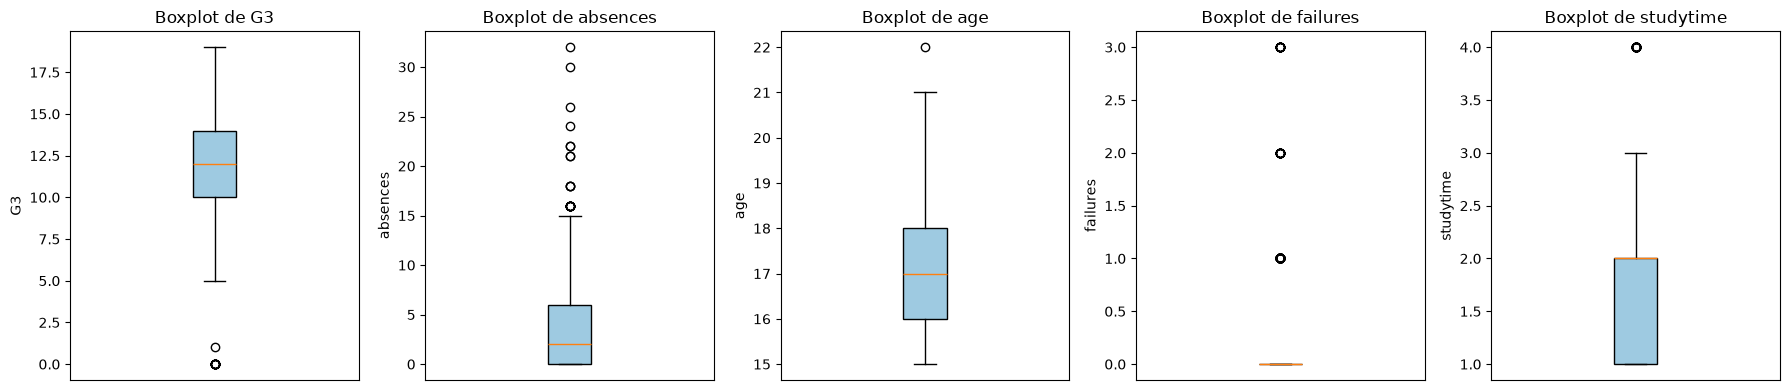

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, variables):
    ax.boxplot(df[col], patch_artist=True, boxprops={"facecolor": "#9ecae1"})
    ax.set_title(f"Boxplot de {col}")
    ax.set_ylabel(col)
    ax.set_xticks([])
plt.tight_layout()
plt.savefig(FIG / "ae1_boxplots.png", dpi=120)
plt.show()

In [22]:
def resumen_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"Q1": q1, "Q3": q3, "limite_inferior": inferior, "limite_superior": superior,
                      "atipicos": ((serie < inferior) | (serie > superior)).sum()})


df[variables].apply(resumen_iqr).T

,Q1,Q3,limite_inferior,limite_superior,atipicos
G3,10.0,14.0,4.0,20.0,16.0
absences,0.0,6.0,-9.0,15.0,21.0
age,16.0,18.0,13.0,21.0,1.0
failures,0.0,0.0,0.0,0.0,100.0
studytime,1.0,2.0,-0.5,3.5,35.0


| Variable | Comportamiento | ¿Válido o error? | Tratamiento propuesto |
|---|---|---|---|
| `G3` | 16 atípicos por debajo de 4 (los 15 ceros y un 1) | Los ceros representan abandono, no desempeño real | Marcar como abandono y excluir del modelado |
| `absences` | 21 alumnos con más de 15 faltas, máximo 32 | **Válidos**: es posible faltar mucho y está dentro del rango documentado (0 a 93) | No eliminar; recortar a 15 (*capping*) para el modelado |
| `age` | 1 alumno de 22 años | **Válido**: el rango documentado es 15 a 22 (alumno con rezago) | Conservar |
| `failures` | Como Q1 = Q3 = 0, todo valor mayor que 0 sale como atípico (100) | **Válidos**: el IQR no es adecuado para variables tan concentradas | Conservar; tratar como variable discreta |
| `studytime` | 35 alumnos con valor 4 (más de 10 horas) | **Válidos**: es una categoría legítima de la escala | Conservar |

No se elimina ningún valor en esta actividad.

## 8. Visualización inicial

### Gráfica 1. Distribución de la calificación final (histograma)

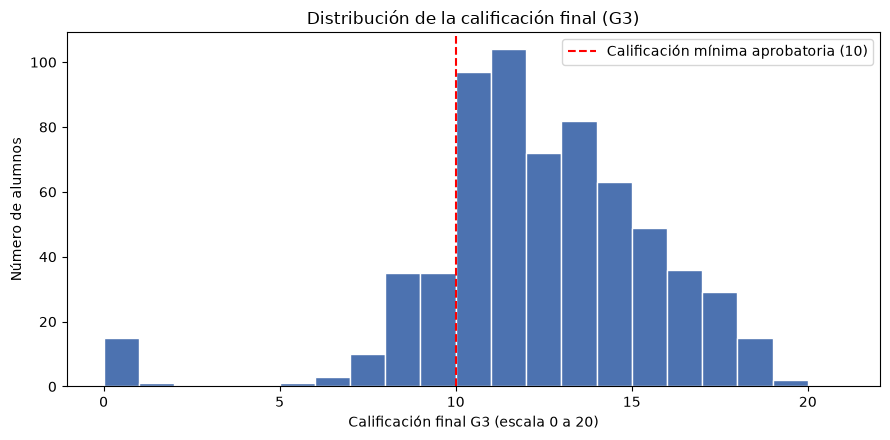

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df["G3"], bins=range(0, 22), color="#4C72B0", edgecolor="white")
ax.axvline(10, color="red", linestyle="--", label="Calificación mínima aprobatoria (10)")
ax.set_title("Distribución de la calificación final (G3)")
ax.set_xlabel("Calificación final G3 (escala 0 a 20)")
ax.set_ylabel("Número de alumnos")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "ae1_g1_histograma_G3.png", dpi=120)
plt.show()

**Interpretación:** la mayoría de los alumnos se concentra entre 10 y 15 puntos, es decir, aprueba. A la
izquierda de la línea roja están los alumnos que no aprobaron. Destaca un grupo separado en 0, que
corresponde a los abandonos detectados en la sección 5.3.

### Gráfica 2. Aprobados y no aprobados (barras)

Se calcula una serie auxiliar con el criterio G3 ≥ 10. **No se agrega al DataFrame original.**

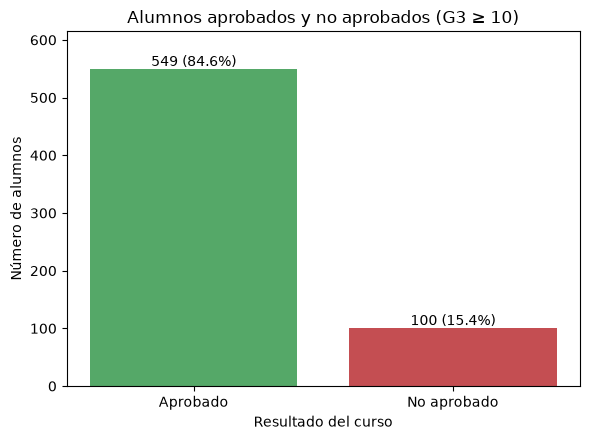

In [24]:
resultado = pd.Series(np.where(df["G3"] >= 10, "Aprobado", "No aprobado")).value_counts()

fig, ax = plt.subplots(figsize=(6, 4.5))
barras = ax.bar(resultado.index, resultado.values, color=["#55A868", "#C44E52"])
ax.bar_label(barras, labels=[f"{v} ({v / len(df):.1%})" for v in resultado.values])
ax.set_ylim(0, resultado.max() * 1.12)
ax.set_title("Alumnos aprobados y no aprobados (G3 ≥ 10)")
ax.set_xlabel("Resultado del curso")
ax.set_ylabel("Número de alumnos")
plt.tight_layout()
plt.savefig(FIG / "ae1_g2_aprobados.png", dpi=120)
plt.show()

**Interpretación:** 549 alumnos (84.6 %) aprobaron y 100 (15.4 %) no. Las **clases están desbalanceadas**,
así que en la Unidad III el modelo de clasificación deberá evaluarse con *recall* y F1, y no solo con
*accuracy*. Un modelo que dijera "todos aprueban" acertaría el 84.6 % sin detectar a ningún alumno en riesgo.

### Gráfica 3. Relación entre G2 y G3 (dispersión)

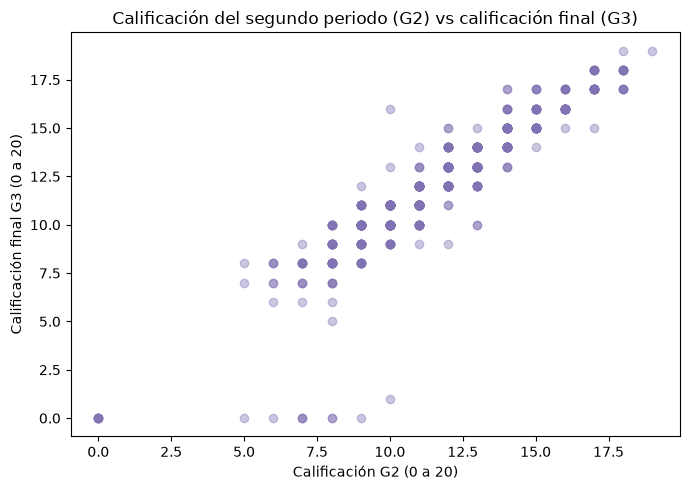

np.float64(0.92)

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["G2"], df["G3"], alpha=0.4, color="#8172B3")
ax.set_title("Calificación del segundo periodo (G2) vs calificación final (G3)")
ax.set_xlabel("Calificación G2 (0 a 20)")
ax.set_ylabel("Calificación final G3 (0 a 20)")
plt.tight_layout()
plt.savefig(FIG / "ae1_g3_dispersion_G2_G3.png", dpi=120)
plt.show()

df["G2"].corr(df["G3"]).round(2)

**Interpretación:** los puntos forman casi una línea recta (correlación de 0.92): quien tuvo buena
calificación en G2 casi siempre tiene buena calificación final. Los puntos aislados en G3 = 0 son los
abandonos. Esto confirma que G2 es muy buena predictora, pero también que usarla puede ser **fuga de
información**: cuando G2 ya se conoce, el curso casi terminó.

### Gráfica 4. Calificación final promedio según reprobadas previas (barras)

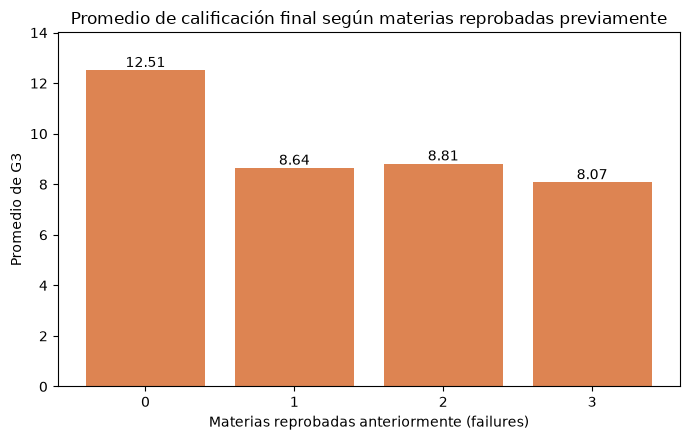

In [26]:
promedio_failures = df.groupby("failures")["G3"].mean()

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(promedio_failures.index.astype(str), promedio_failures.values, color="#DD8452")
ax.bar_label(barras, fmt="%.2f")
ax.set_ylim(0, promedio_failures.max() * 1.12)
ax.set_title("Promedio de calificación final según materias reprobadas previamente")
ax.set_xlabel("Materias reprobadas anteriormente (failures)")
ax.set_ylabel("Promedio de G3")
plt.tight_layout()
plt.savefig(FIG / "ae1_g4_G3_por_failures.png", dpi=120)
plt.show()

**Interpretación:** los alumnos sin reprobadas previas promedian 12.5, mientras que quienes reprobaron al
menos una vez bajan a menos de 9 (por debajo de la calificación aprobatoria). Haber reprobado antes es una
señal fuerte de riesgo.

### Gráfica 5. Matriz de correlación de variables numéricas

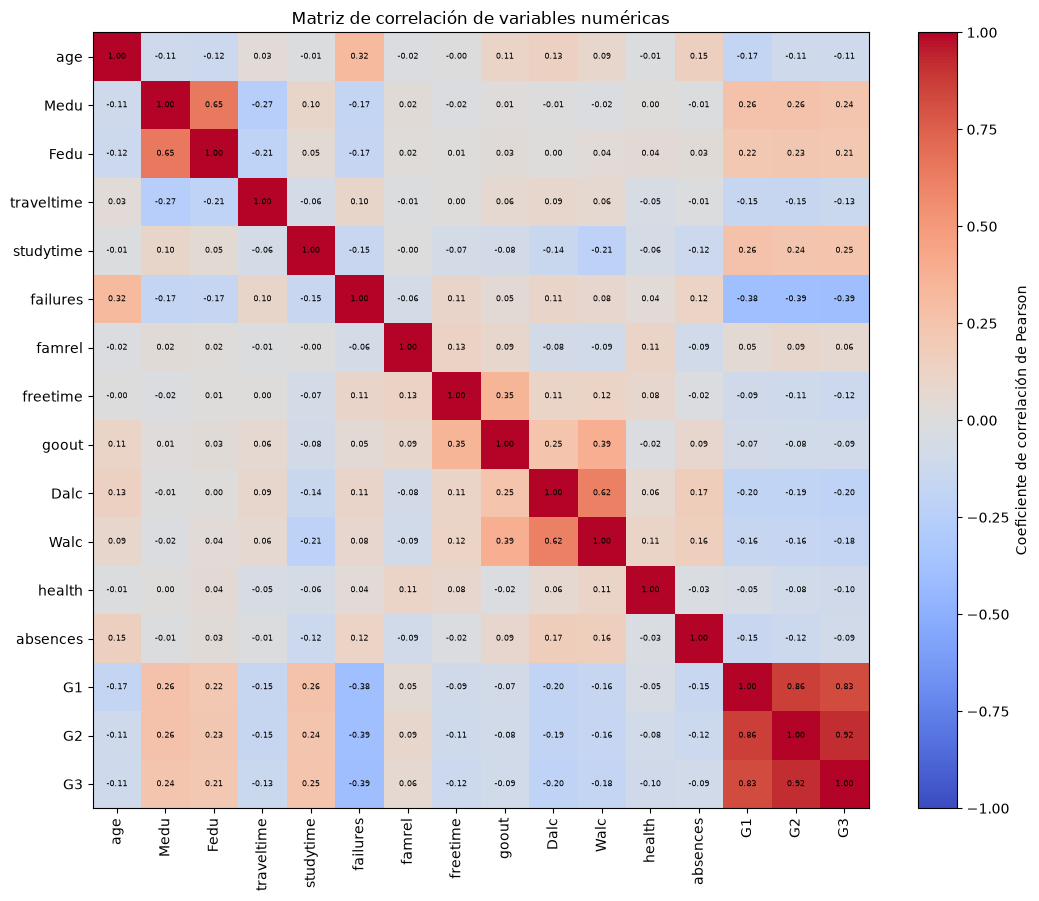

failures     -0.39
Dalc         -0.20
Walc         -0.18
traveltime   -0.13
freetime     -0.12
age          -0.11
health       -0.10
absences     -0.09
goout        -0.09
famrel        0.06
Fedu          0.21
Medu          0.24
studytime     0.25
G1            0.83
G2            0.92
Name: G3, dtype: float64

In [27]:
corr = df.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(11, 9))
imagen = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(imagen, ax=ax, label="Coeficiente de correlación de Pearson")
ax.set_title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.savefig(FIG / "ae1_g5_correlacion.png", dpi=120)
plt.show()

corr["G3"].drop("G3").sort_values().round(2)

**Interpretación:**
- Además de G1 (0.83) y G2 (0.92), las variables más relacionadas con G3 son `failures` (−0.39),
  `studytime` (0.25), `Medu` (0.24), `Fedu` (0.21) y el consumo de alcohol (`Dalc` −0.20, `Walc` −0.18).
- Estas relaciones son **moderadas o débiles**: ninguna variable personal o social explica por sí sola la
  calificación.
- Correlación no implica causalidad.

## 9. Preparación para análisis posteriores

| Análisis | Propuesta | Justificación con el problema de la Unidad I |
|---|---|---|
| **Regresión** | **Objetivo:** `G3`, para predecir la calificación final numérica (0 a 20). **Entradas:** `failures`, `studytime`, `Medu`, `Fedu`, `higher`, `school`, `absences`, `Dalc`, `Walc`, `goout`, `age` y, en un segundo escenario, `G1` y `G2` | El proyecto busca anticipar el desempeño final. Comparar los dos escenarios (con y sin parciales) mide cuánto aportan los factores personales y sociales |
| **Clasificación** | **Objetivo:** variable derivada de G3. **Clases:** *Aprobado* (G3 ≥ 10) / *No aprobado* (G3 < 10); alternativa de tres niveles: *Bajo* (0-9), *Medio* (10-13), *Alto* (14-20) | Responde directamente a la pregunta de detectar a tiempo a los alumnos en riesgo de reprobar. El corte en 10 es la calificación aprobatoria de la escala portuguesa |
| **Agrupamiento** | **Variables:** `studytime`, `failures`, `absences`, `goout`, `freetime`, `Dalc`, `Walc`, `famrel`, `Medu`, `Fedu`, `health` | Permiten formar perfiles de estudiantes según hábitos, vida social y entorno familiar sin usar la calificación. Después, G3 servirá para identificar qué grupo concentra más alumnos en riesgo |

## 10. Conclusión del diagnóstico

1. **¿Qué información contiene el dataset?** Datos de 649 estudiantes de bachillerato de dos escuelas de
   Portugal: tres calificaciones del curso de Portugués y 30 características demográficas, familiares,
   sociales y de hábitos de estudio.
2. **¿Cuál es su nivel general de calidad?** **Alto.** Es una fuente estructurada, completa y sin duplicados,
   con valores dentro de los rangos documentados y categorías bien escritas.
3. **¿Qué problemas fueron identificados?**
   - 15 alumnos con G3 = 0 (abandono).
   - 7 con G2 = 0.
   - 1 alumno con G1 = 0 que parece dato no capturado.
   - Faltas muy asimétricas, con 21 atípicos.
   - Clases desbalanceadas (84.6 % / 15.4 %).
   - Variables ordinales codificadas como números.
4. **¿Qué variables requieren tratamiento?**
   - `G1`, `G2` y `G3`: casos en cero.
   - `absences`: atípicos.
   - Las 17 variables de texto: deben codificarse.
   - Las numéricas: requerirán escalamiento para clustering.
5. **¿Existen valores faltantes?** No, 0 en todas las variables.
6. **¿Existen registros duplicados?** No, 0.
7. **¿Existen valores atípicos?** Sí:
   - En `absences` (21) y `G3` (16).
   - El 1 caso de `age` y los de `failures` y `studytime` son valores válidos.
8. **¿Qué transformaciones serán necesarias?**
   - Marcar los abandonos.
   - Recortar las faltas atípicas.
   - Codificar binarias a 0/1 y nominales con one-hot.
   - Crear la variable de clase (aprobado / nivel de desempeño).
   - Escalar las variables para clustering y PCA.
   - Cargar los datos procesados a un Data Mart.
9. **¿Los datos son adecuados para continuar?** **Sí.** Tienen buena calidad, contienen una variable objetivo
   clara (G3) y variables explicativas con relación con ella. Los problemas detectados se corrigen con
   transformaciones sencillas.
10. **¿Qué conocimiento podría obtenerse?**
    - Qué factores (reprobaciones previas, tiempo de estudio, escolaridad de los padres, aspiración a estudios
      superiores) influyen más en la calificación final.
    - Un modelo de alerta temprana para detectar alumnos con riesgo de reprobar.
    - Perfiles de estudiantes que ayuden a la escuela a dirigir tutorías y apoyos.